# Input Data

In [321]:
import pandas as pd

In [322]:
df1 = pd.read_excel("D:\csv\WorldHappiness_Corruption_2015_2020.xlsx")
df1

,Country,happiness_score,gdp_per_capita,family,health,freedom,generosity,government_trust,dystopia_residual,continent,Year,social_support,cpi_score
0,Norway,7.5370,1.616463,1.533524,0.796667,0.635423,0.362012,0.315964,2.277027,Europe,2015,0.000000,88
1,Denmark,7.5220,1.482383,1.551122,0.792566,0.626007,0.355280,0.400770,2.313707,Europe,2015,0.000000,91
2,Iceland,7.5040,1.480633,1.610574,0.833552,0.627163,0.475540,0.153527,2.322715,Europe,2015,0.000000,79
3,Switzerland,7.4940,1.564980,1.516912,0.858131,0.620071,0.290549,0.367007,2.276716,Europe,2015,0.000000,86
4,Finland,7.4690,1.443572,1.540247,0.809158,0.617951,0.245483,0.382612,2.430182,Europe,2015,0.000000,90
...,...,...,...,...,...,...,...,...,...,...,...,...,...
787,Botswana,3.4789,0.997549,0.000000,0.494102,0.509089,0.033407,0.101786,0.257241,Africa,2020,1.085695,60
788,Tanzania,3.4762,0.457163,0.000000,0.442678,0.509343,0.271541,0.203881,0.718963,Africa,2020,0.872675,38
789,Rwanda,3.3123,0.343243,0.000000,0.572383,0.604088,0.235705,0.485542,0.548445,Africa,2020,0.522876,54
790,Zimbabwe,3.2992,0.425564,0.000000,0.375038,0.377405,0.151349,0.080929,0.841031,Africa,2020,1.047835,24


# Transformasi Data

## Cek Missing value

In [323]:
# Menghitung jumlah nilai '0' per variabel
jumlah_nilai_nol_per_variabel = (df1 == 0).sum()

print("Jumlah nilai '0' per variabel sebelum imputasi:")
print(jumlah_nilai_nol_per_variabel)
print("karena telah diimputasi dengan nilai mean maka nilai 0 pada tiap variabel sudah tidak ada pada dataframe")

Jumlah nilai '0' per variabel sebelum imputasi:
Country                0
happiness_score        0
gdp_per_capita         1
family               397
health                 3
freedom                3
generosity             6
government_trust       7
dystopia_residual    264
continent              0
Year                   0
social_support       396
cpi_score              0
dtype: int64
karena telah diimputasi dengan nilai mean maka nilai 0 pada tiap variabel sudah tidak ada pada dataframe


## Time series analysis

In [457]:
# creat pivot table

piv_avg=df1.pivot_table(index="continent",columns="Year",values="happiness_score")
piv_avg.round(2)

Year,2015,2016,2017,2018,2019,2020
continent,,,,,,
Africa,4.31,4.29,4.43,4.36,4.28,4.47
Asia,5.28,5.26,5.25,5.26,5.26,5.28
Australia,7.30,7.28,7.27,7.30,7.32,7.26
Europe,6.13,6.08,6.29,6.20,6.09,6.38
North America,6.96,7.24,6.92,6.90,7.10,6.88
South America,5.79,5.96,5.84,5.81,5.89,5.90


## Time series analysis score_happiness seluruh benua

<AxesSubplot:xlabel='continent'>

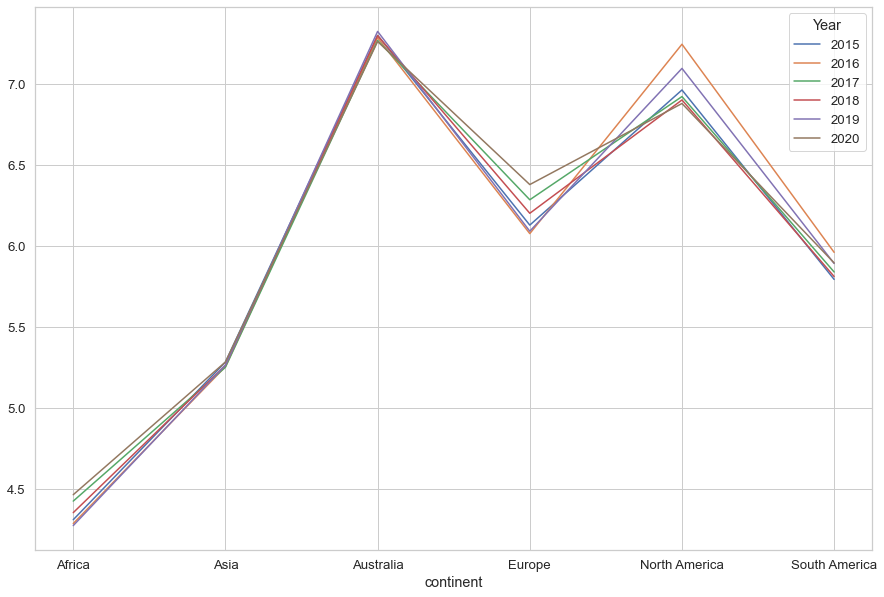

In [412]:
piv_avg.plot(figsize=(15,10))

In [413]:
# now create new table filter by continent 

africa= df1[df1["continent"]=="Africa"]
asia= df1[df1["continent"]=="Asia"]
australia= df1[df1["continent"]=="Australia"]
europe= df1[df1["continent"]=="Europe"]
north_a= df1[df1["continent"]=="North America"]
south_a= df1[df1["continent"]=="South America"]

In [414]:
# create pivot table - asia

asia_p=asia.pivot_table(index="Country",columns="Year",values="happiness_score")
asia_p.sort_values(by=2015)

Year,2015,2016,2017,2018,2019,2020
Country,,,,,,
Yemen,3.593,4.077,3.380,3.355,3.724,3.5274
Afghanistan,3.794,3.575,3.203,3.632,3.360,2.5669
Cambodia,4.168,3.819,4.700,4.433,3.907,4.8484
Georgia,4.286,4.297,4.519,4.340,4.252,4.6726
India,4.315,4.565,4.015,4.190,4.404,3.5733
Armenia,4.376,4.350,4.559,4.321,4.360,4.6768
Sri Lanka,4.440,4.271,4.366,4.471,4.415,4.3270
Iraq,4.497,4.677,4.437,4.456,4.575,4.7848
Myanmar,4.545,4.307,4.360,4.308,4.395,4.3080


<AxesSubplot:xlabel='Country'>

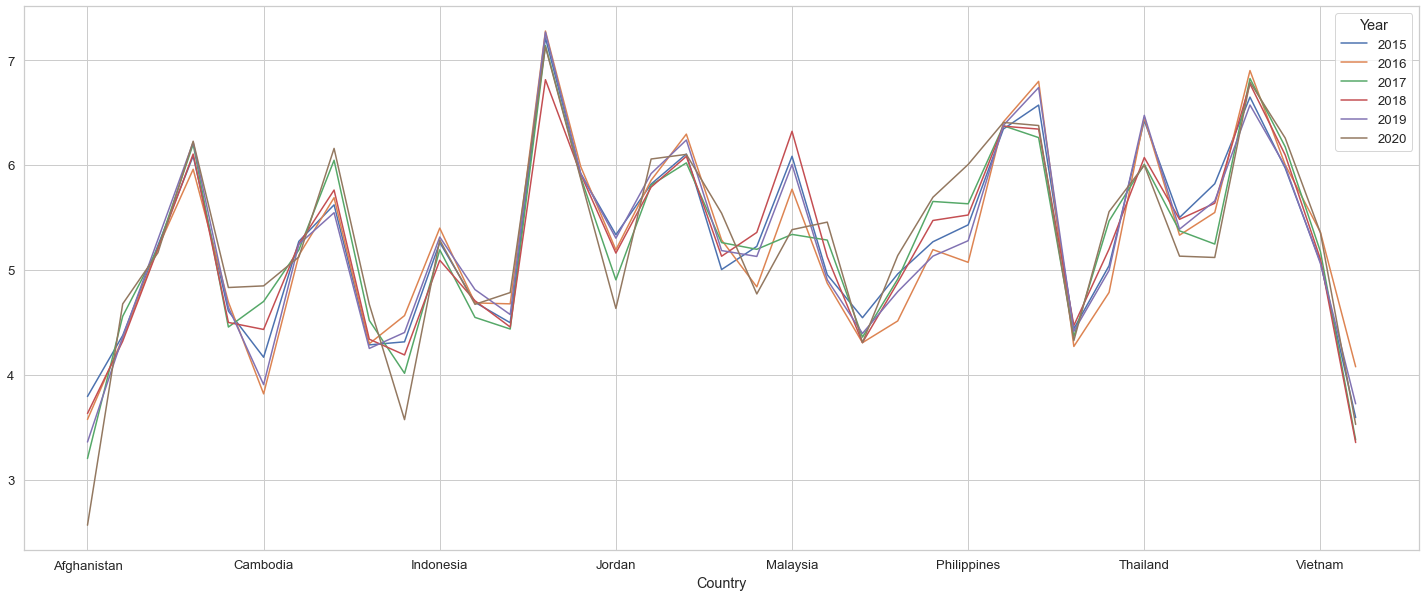

In [415]:
asia_p.plot(figsize=(25,10))

# Imputasi Mean

In [277]:
df1.mean()

C:\Users\Gorfy\AppData\Local\Temp\ipykernel_13848\2053335143.py:1: FutureWarning:

Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.



happiness_score         5.473310
gdp_per_capita          0.929217
family                  0.504998
health                  0.648691
freedom                 0.427016
generosity              0.212440
government_trust        0.125720
dystopia_residual       1.379277
Year                 2017.500000
social_support          0.609302
cpi_score              44.327020
dtype: float64

In [278]:
columns_with_missing_values = ['family', 'freedom', 'gdp_per_capita', 'generosity', 'health', 'government_trust', 'social_support', 'dystopia_residual']

for column in columns_with_missing_values:
    mean_value = df1[column].mean()
    df1[column] = df1[column].replace(0, mean_value)

df1

,Country,happiness_score,gdp_per_capita,family,health,freedom,generosity,government_trust,dystopia_residual,continent,Year,social_support,cpi_score
0,Norway,7.5370,1.616463,1.533524,0.796667,0.635423,0.362012,0.315964,2.277027,Europe,2015,0.609302,88
1,Denmark,7.5220,1.482383,1.551122,0.792566,0.626007,0.355280,0.400770,2.313707,Europe,2015,0.609302,91
2,Iceland,7.5040,1.480633,1.610574,0.833552,0.627163,0.475540,0.153527,2.322715,Europe,2015,0.609302,79
3,Switzerland,7.4940,1.564980,1.516912,0.858131,0.620071,0.290549,0.367007,2.276716,Europe,2015,0.609302,86
4,Finland,7.4690,1.443572,1.540247,0.809158,0.617951,0.245483,0.382612,2.430182,Europe,2015,0.609302,90
...,...,...,...,...,...,...,...,...,...,...,...,...,...
787,Botswana,3.4789,0.997549,0.504998,0.494102,0.509089,0.033407,0.101786,0.257241,Africa,2020,1.085695,60
788,Tanzania,3.4762,0.457163,0.504998,0.442678,0.509343,0.271541,0.203881,0.718963,Africa,2020,0.872675,38
789,Rwanda,3.3123,0.343243,0.504998,0.572383,0.604088,0.235705,0.485542,0.548445,Africa,2020,0.522876,54
790,Zimbabwe,3.2992,0.425564,0.504998,0.375038,0.377405,0.151349,0.080929,0.841031,Africa,2020,1.047835,24


### CEK DUPLIKASI VALUE CPI_SCORE

In [422]:
# Mengecek duplikasi berdasarkan seluruh baris
duplikasi_total = df1.duplicated()

# Mengecek duplikasi berdasarkan kolom tertentu
duplikasi_kolom = df1.duplicated(subset=['cpi_score'])

# Menampilkan baris yang merupakan duplikat
duplikat = df1[df1.duplicated()]

# Menampilkan semua baris yang memiliki duplikat berdasarkan kolom tertentu
duplikat_kolom = df1[df1.duplicated(subset=['cpi_score'])]

print("Duplikasi Total:")
print(duplikasi_total)

print("\nDuplikasi Berdasarkan Kolom Nama:")
print(duplikasi_kolom)

print("\nBaris yang merupakan Duplikat:")
print(duplikat)

print("\nDuplikat Berdasarkan Kolom Nama:")
print(duplikat_kolom)


Duplikasi Total:
0      False
1      False
2      False
3      False
4      False
       ...  
787    False
788    False
789    False
790    False
791    False
Length: 792, dtype: bool

Duplikasi Berdasarkan Kolom Nama:
0      False
1      False
2      False
3      False
4      False
       ...  
787     True
788     True
789     True
790     True
791     True
Length: 792, dtype: bool

Baris yang merupakan Duplikat:
Empty DataFrame
Columns: [Country, happiness_score, gdp_per_capita, family, health, freedom, generosity, government_trust, dystopia_residual, continent, Year, social_support, cpi_score]
Index: []

Duplikat Berdasarkan Kolom Nama:
                  Country  happiness_score  gdp_per_capita    family  \
7             New Zealand           7.3140        1.405706  1.548195   
9               Australia           7.2840        1.484415  1.510042   
13          United States           6.9930        1.546259  1.419921   
18         United Kingdom           6.7140        1.441634  1.

# INTEGRASI DATA

## Pengecekan Oulier Dataset untuk Data Cleaning

In [12]:
import pandas as pd
import numpy as np

# Menghitung kuartil pertama (Q1) dan kuartil ketiga (Q3)
Q1 = df1['happiness_score'].quantile(0.25)
Q3 = df1['happiness_score'].quantile(0.75)

# Menghitung IQR (Interquartile Range)
IQR = Q3 - Q1

# Menentukan batas bawah dan batas atas untuk outlier
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

# Mengidentifikasi outlier
outliers = df1[(df1['happiness_score'] < batas_bawah) | (df1['happiness_score'] > batas_atas)]

print("Nilai-nilai yang termasuk outlier:")
print(outliers)


Nilai-nilai yang termasuk outlier:
Empty DataFrame
Columns: [Country, happiness_score, gdp_per_capita, family, health, freedom, generosity, government_trust, dystopia_residual, continent, Year, social_support, cpi_score]
Index: []


## boxplot

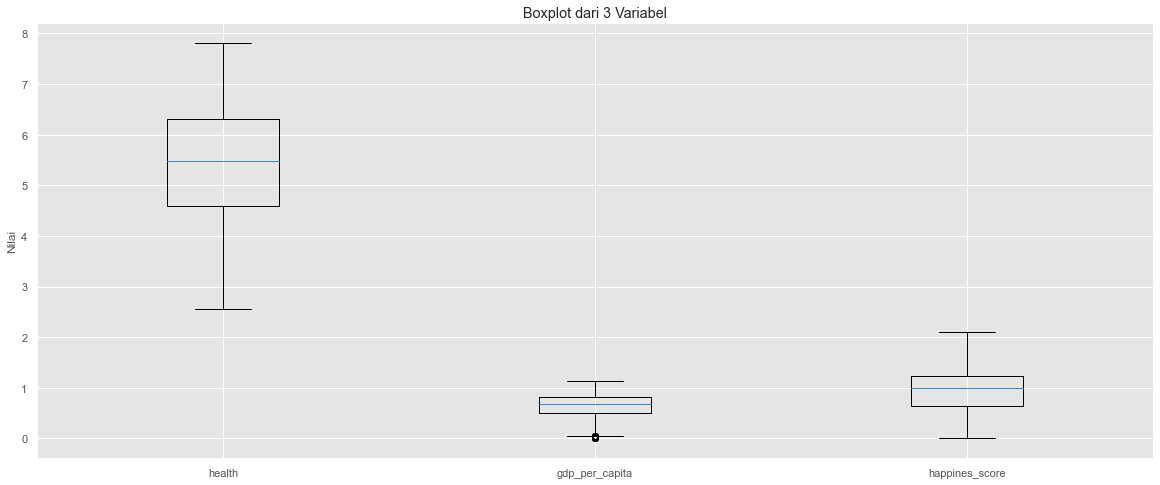

In [331]:
import matplotlib.pyplot as plt
import pandas as pd

# Membuat boxplot
plt.figure(figsize=(20, 8))
plt.boxplot([df1['happiness_score'], df1['health'], df1['gdp_per_capita']], labels=['health', 'gdp_per_capita', 'happines_score'])
plt.title('Boxplot dari 3 Variabel')
plt.ylabel('Nilai')
plt.show()


# IQR

In [28]:
Q1 = df1['cpi_score'].quantile(0.25)
Q3 = df1['cpi_score'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


In [29]:
outliers = df1[(df1['cpi_score'] < lower_bound) | (df1['cpi_score'] > upper_bound)]

In [30]:
outliers

,Country,happiness_score,gdp_per_capita,family,health,freedom,generosity,government_trust,dystopia_residual,continent,Year,social_support,cpi_score


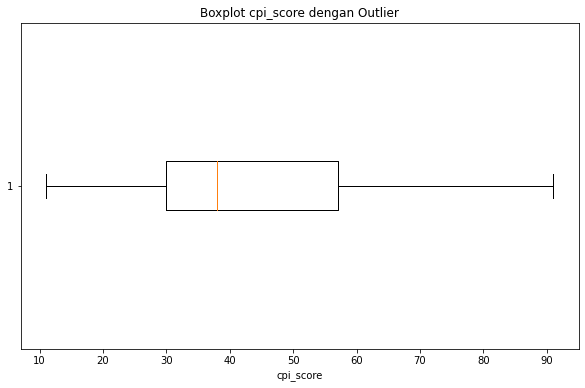

In [31]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.boxplot(df1['gdp_per_capi'], vert=False, whis=1.5)
plt.title('Boxplot cpi_score dengan Outlier')
plt.xlabel('cpi_score')
plt.show()

# Pengecekan konsistensi baris pada tiap' benua dan tahun apakah sama/tidak

In [35]:
size = df1.groupby('Year')
size.count()

,Country,happiness_score,gdp_per_capita,family,health,freedom,generosity,government_trust,dystopia_residual,continent,social_support,cpi_score
Year,,,,,,,,,,,,
2015,132,132,132,132,132,132,132,132,132,132,132,132
2016,132,132,132,132,132,132,132,132,132,132,132,132
2017,132,132,132,132,132,132,132,132,132,132,132,132
2018,132,132,132,132,132,132,132,132,132,132,132,132
2019,132,132,132,132,132,132,132,132,132,132,132,132
2020,132,132,132,132,132,132,132,132,132,132,132,132


In [36]:
size = df1.groupby('continent')
size.count()

,Country,happiness_score,gdp_per_capita,family,health,freedom,generosity,government_trust,dystopia_residual,Year,social_support,cpi_score
continent,,,,,,,,,,,,
Africa,192,192,192,192,192,192,192,192,192,192,192,192
Asia,222,222,222,222,222,222,222,222,222,222,222,222
Australia,12,12,12,12,12,12,12,12,12,12,12,12
Europe,228,228,228,228,228,228,228,228,228,228,228,228
North America,18,18,18,18,18,18,18,18,18,18,18,18
South America,120,120,120,120,120,120,120,120,120,120,120,120


# Pengecekan nilai Nan dan Nol pada tidap variabel setelah dilakukan imputasi di dalam dataframe

In [37]:
# Menghitung jumlah NaN per variabel
jumlah_nan_per_variabel = df1.isnull().sum()

# Menampilkan hasil
print("Jumlah NaN per variabel:")
print(jumlah_nan_per_variabel)

Jumlah NaN per variabel:
Country              0
happiness_score      0
gdp_per_capita       0
family               0
health               0
freedom              0
generosity           0
government_trust     0
dystopia_residual    0
continent            0
Year                 0
social_support       0
cpi_score            0
dtype: int64


## MISSING VALUE SETELAH DILAKUKAN IMPUTASI DATA

In [128]:
# Menghitung jumlah nilai '0' per variabel
jumlah_nilai_nol_per_variabel = (df1 == 0).sum()

print("Jumlah nilai '0' per variabel sebelum imputasi:")
print(jumlah_nilai_nol_per_variabel)
print("karena telah diimputasi dengan nilai mean maka nilai 0 pada tiap variabel sudah tidak ada pada dataframe")

Jumlah nilai '0' per variabel sebelum imputasi:
Country              0
happiness_score      0
gdp_per_capita       0
family               0
health               0
freedom              0
generosity           0
government_trust     0
dystopia_residual    0
continent            0
Year                 0
social_support       0
cpi_score            0
dtype: int64
karena telah diimputasi dengan nilai mean maka nilai 0 sudah tidak ada pada dataframe


In [24]:
df1.dtypes

Country               object
happiness_score      float64
gdp_per_capita       float64
family               float64
health               float64
freedom              float64
generosity           float64
government_trust     float64
dystopia_residual    float64
continent             object
Year                   int64
social_support       float64
cpi_score              int64
dtype: object

# TRANSFORMASI DATA (GROUPING DATA SET)

## Sorting data dalam 5 tahun untuk mengetahui mana yang paling banyak mendominasi

In [310]:
df_drop_new = df1.drop(['social_support', 'family', 'freedom', 'generosity', 'government_trust', 'dystopia_residual', ], axis=1)
df_drop_new

,Country,happiness_score,gdp_per_capita,health,continent,Year,cpi_score
0,Norway,7.5370,1.616463,0.796667,Europe,2015,88
1,Denmark,7.5220,1.482383,0.792566,Europe,2015,91
2,Iceland,7.5040,1.480633,0.833552,Europe,2015,79
3,Switzerland,7.4940,1.564980,0.858131,Europe,2015,86
4,Finland,7.4690,1.443572,0.809158,Europe,2015,90
...,...,...,...,...,...,...,...
787,Botswana,3.4789,0.997549,0.494102,Africa,2020,60
788,Tanzania,3.4762,0.457163,0.442678,Africa,2020,38
789,Rwanda,3.3123,0.343243,0.572383,Africa,2020,54
790,Zimbabwe,3.2992,0.425564,0.375038,Africa,2020,24


In [170]:
df_sorted = df_drop_new.sort_values(by=['happiness_score', 'continent', 'Year'], ascending=False)

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_sorted.head(10)
print("\nTop 10 Upper Happiness Scores:")
print(top_5_happiness[['Country', 'happiness_score', 'continent', 'Year']])


Top 5 Upper Happiness Scores:
         Country  happiness_score continent  Year
660      Finland           7.8087    Europe  2020
264      Finland           7.7690    Europe  2017
661      Denmark           7.6456    Europe  2020
396      Finland           7.6320    Europe  2018
265      Denmark           7.6000    Europe  2017
397       Norway           7.5940    Europe  2018
132  Switzerland           7.5870    Europe  2016
133      Iceland           7.5610    Europe  2016
662  Switzerland           7.5599    Europe  2020
398      Denmark           7.5550    Europe  2018


In [311]:
df_sorted = df_drop_new.sort_values(by=['happiness_score', 'continent', 'Year'], ascending=True)

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_sorted.head(10)
print("\nTop 5 Lower Happiness Scores:")
print(top_5_happiness[['Country', 'happiness_score', 'continent', 'Year']])


Top 5 Lower Happiness Scores:
         Country  happiness_score continent  Year
791  Afghanistan           2.5669      Asia  2020
263         Togo           2.8390    Africa  2016
131      Burundi           2.9050    Africa  2015
262      Burundi           2.9050    Africa  2016
527      Burundi           2.9050    Africa  2018
659      Burundi           2.9050    Africa  2019
395  Afghanistan           3.2030      Asia  2017
394     Tanzania           3.2310    Africa  2017
790     Zimbabwe           3.2992    Africa  2020
526     Tanzania           3.3030    Africa  2018


## ANALISIS TOP 10 UPPER DAN LOWER UNTUK BENUA ASIA (CPI_SCORE & HAPPINES)

In [288]:
years_to_exclude = []  # Ganti dengan tahun yang ingin dihilangkan
df_selected_years = df_drop_new[(~df_drop_new['Year'].isin(years_to_exclude)) & (df_drop_new['continent'] == 'Asia')]
df_selected_years


,Country,happiness_score,gdp_per_capita,health,continent,Year,cpi_score
10,Israel,7.2130,1.375382,0.838404,Asia,2015,61
20,United Arab Emirates,6.6480,1.626343,0.726798,Asia,2015,70
24,Singapore,6.5720,1.692278,0.949492,Asia,2015,85
30,Thailand,6.4240,1.127869,0.647239,Asia,2015,38
33,Saudi Arabia,6.3440,1.530624,0.590148,Asia,2015,52
...,...,...,...,...,...,...,...
774,Sri Lanka,4.3270,0.897987,0.792037,Asia,2020,38
775,Myanmar,4.3080,0.678091,0.495443,Asia,2020,28
784,India,3.5733,0.730576,0.540570,Asia,2020,40
786,Yemen,3.5274,0.392702,0.415000,Asia,2020,15


In [287]:
df_selected_years.describe()

,happiness_score,gdp_per_capita,health,Year,cpi_score
count,222.000000,222.000000,222.000000,222.000000,222.000000
mean,5.267553,0.946647,0.660561,2017.500000,38.076577
std,0.865918,0.346703,0.171948,1.711685,16.119140
min,2.566900,0.271080,0.173440,2015.000000,11.000000
25%,4.672450,0.698820,0.547144,2016.000000,28.000000
50%,5.239500,0.965950,0.649348,2017.500000,35.500000
75%,5.950250,1.171855,0.767178,2019.000000,46.750000
max,7.278000,2.096000,1.141000,2020.000000,85.000000


<AxesSubplot:xlabel='Year', ylabel='happiness_score'>

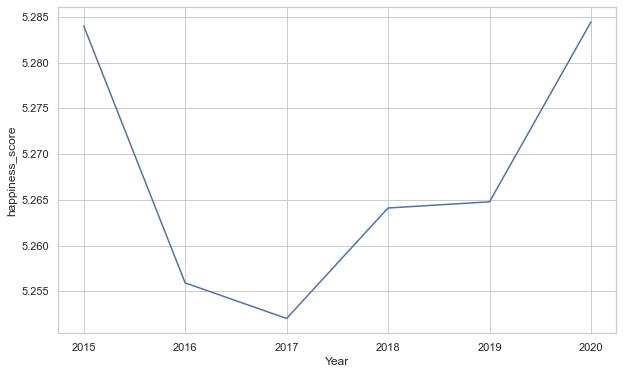

In [290]:
# Prepare data for visualization
plt.figure(figsize=(10,6))
sns.lineplot(data=df_selected_years.reset_index(),x='Year', y='happiness_score',ci=None)

<AxesSubplot:xlabel='Year', ylabel='cpi_score'>

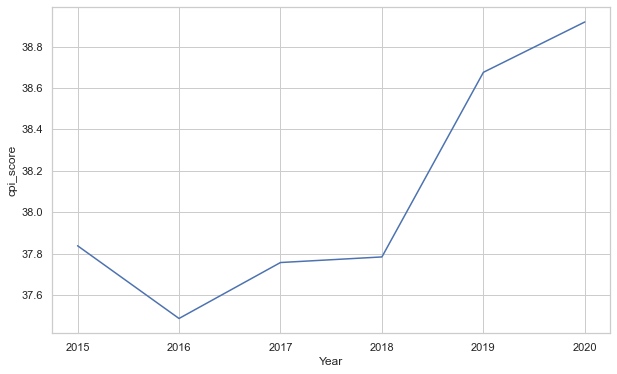

In [291]:
# Prepare data for visualization
plt.figure(figsize=(10,6))
sns.lineplot(data=df_selected_years.reset_index(),x='Year', y='cpi_score',ci=None)

<AxesSubplot:xlabel='Year', ylabel='health'>

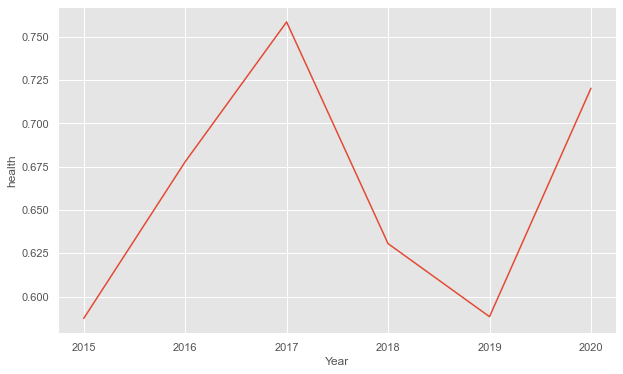

In [308]:
# Prepare data for visualization
plt.figure(figsize=(10,6))
sns.lineplot(data=df_selected_years.reset_index(),x='Year', y='health',ci=None)

<AxesSubplot:xlabel='Year', ylabel='gdp_per_capita'>

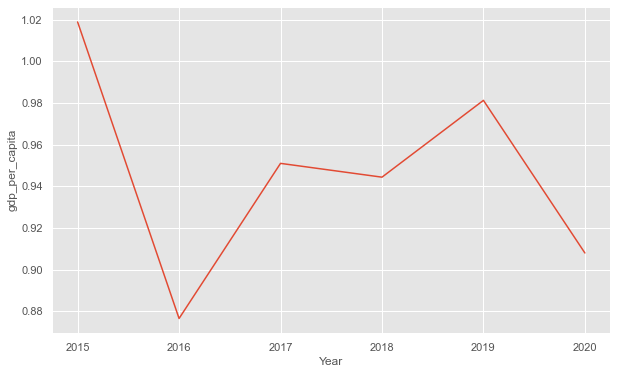

In [309]:
# Prepare data for visualization
plt.figure(figsize=(10,6))
sns.lineplot(data=df_selected_years.reset_index(),x='Year', y='gdp_per_capita',ci=None)

## TAHUN 2015

In [371]:
years_to_include = [2015]
df_selected_years = df_drop_new[(df_drop_new['Year'].isin(years_to_include)) & (df_drop_new['continent'] == 'Asia')]
df_selected_years

,Country,happiness_score,gdp_per_capita,health,continent,Year,cpi_score
10,Israel,7.213,1.375382,0.838404,Asia,2015,61
20,United Arab Emirates,6.648,1.626343,0.726798,Asia,2015,70
24,Singapore,6.572,1.692278,0.949492,Asia,2015,85
30,Thailand,6.424,1.127869,0.647239,Asia,2015,38
33,Saudi Arabia,6.344,1.530624,0.590148,Asia,2015,52
34,Kuwait,6.105,1.632952,0.632106,Asia,2015,49
36,Bahrain,6.087,1.488412,0.653133,Asia,2015,51
37,Malaysia,6.084,1.291215,0.618784,Asia,2015,50
42,Uzbekistan,5.971,0.786441,0.498273,Asia,2015,19
45,Japan,5.920,1.416915,0.913476,Asia,2015,75


In [388]:
df_sorted = df_selected_years.sort_values(by=['cpi_score'], ascending=False)

# Memfilter DataFrame hanya untuk baris yang memiliki cpi_score > 50
df_filtered = df_sorted[df_sorted['cpi_score'] < 50]

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_filtered.iloc[1:11]
print("\n2015 Top 10 Happiness Scores with CPI Score < 50:")
sorting = top_5_happiness[['Country', 'happiness_score', 'cpi_score', 'gdp_per_capita', 'health']]
sorting = sorting.sort_values(by="happiness_score", ascending=False)
sorted = sorting.reset_index()
to_drop = ["index"]
sorted.drop(columns=to_drop, inplace=True)
sorted


2015 Top 10 Happiness Scores with CPI Score < 50:


,Country,happiness_score,cpi_score,gdp_per_capita,health
0,Thailand,6.424,38,1.127869,0.647239
1,Turkey,5.500,42,1.198274,0.637606
2,Philippines,5.430,35,0.857699,0.468009
3,China,5.273,37,1.081166,0.741416
4,Indonesia,5.262,36,0.995539,0.492346
5,Vietnam,5.074,31,0.788548,0.652169
6,Mongolia,4.955,39,1.027236,0.557783
7,Sri Lanka,4.440,37,1.009850,0.625131
8,Armenia,4.376,35,0.900597,0.637524
9,India,4.315,38,0.792221,0.455428


In [392]:
df_sorted = df_selected_years.sort_values(by=['cpi_score'], ascending=False)

# Memfilter DataFrame hanya untuk baris yang memiliki cpi_score > 50
df_filtered = df_sorted[df_sorted['cpi_score'] > 50]

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_filtered.iloc[1:11]
print("2015 Top 7 Happiness Scores with CPI Score > 50: (because there are only 8 countries that held cpi_score more than 50")
sorting = top_5_happiness[['Country', 'happiness_score', 'cpi_score', 'gdp_per_capita', 'health']]
sorting = sorting.sort_values(by="happiness_score", ascending=False)
sorted = sorting.reset_index()
to_drop = ["index"]
sorted.drop(columns=to_drop, inplace=True)
sorted

2015 Top 7 Happiness Scores with CPI Score > 50: (because there are only 8 countries that held cpi_score more than 50


,Country,happiness_score,cpi_score,gdp_per_capita,health
0,Israel,7.213,61,1.375382,0.838404
1,United Arab Emirates,6.648,70,1.626343,0.726798
2,Saudi Arabia,6.344,52,1.530624,0.590148
3,Bahrain,6.087,51,1.488412,0.653133
4,Japan,5.920,75,1.416915,0.913476
5,Cyprus,5.621,61,1.355938,0.844715
6,Jordan,5.336,53,0.991012,0.604590
7,Georgia,4.286,52,0.950613,0.649547


In [372]:
df_selected_years.describe()

,happiness_score,gdp_per_capita,health,Year,cpi_score
count,37.000000,37.000000,37.000000,37.0,37.000000
mean,5.284027,1.018838,0.587419,2015.0,37.837838
std,0.840452,0.360791,0.157570,0.0,17.255456
min,3.593000,0.367111,0.180747,2015.0,11.000000
25%,4.608000,0.786441,0.498273,2015.0,27.000000
50%,5.262000,1.027236,0.604590,2015.0,35.000000
75%,5.920000,1.284556,0.649547,2015.0,50.000000
max,7.213000,1.692278,0.949492,2015.0,85.000000


# Tahun 2016

In [433]:
years_to_include = [2016]
df_selected_years = df_drop_new[(df_drop_new['Year'].isin(years_to_include)) & (df_drop_new['continent'] == 'Asia')]
df_selected_years

,Country,happiness_score,gdp_per_capita,health,continent,Year,cpi_score
142,Israel,7.278,1.22857,0.91387,Asia,2016,64
151,United Arab Emirates,6.901,1.42727,0.80925,Asia,2016,66
154,Singapore,6.798,1.52186,1.02525,Asia,2016,84
162,Thailand,6.455,0.96690,0.73850,Asia,2016,35
163,Saudi Arabia,6.411,1.39541,0.72025,Asia,2016,46
166,Kuwait,6.295,1.55422,0.72492,Asia,2016,41
169,Uzbekistan,6.003,0.63244,0.59772,Asia,2016,21
171,Japan,5.987,1.27074,0.99111,Asia,2016,72
173,Bahrain,5.960,1.32376,0.74716,Asia,2016,43
178,Kazakhstan,5.855,1.12254,0.64368,Asia,2016,29


In [434]:
df_sorted = df_selected_years.sort_values(by=['cpi_score'], ascending=False)

# Memfilter DataFrame hanya untuk baris yang memiliki cpi_score > 50
df_filtered = df_sorted[df_sorted['cpi_score'] < 50]

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_filtered.iloc[1:11]
print("\n2016 - Top 10 Happiness Scores with CPI Score < 50:")
sorting = top_5_happiness[['Country', 'happiness_score', 'cpi_score', 'gdp_per_capita', 'health']]
sorting = sorting.sort_values(by="happiness_score", ascending=False)
sorted = sorting.reset_index()
to_drop = ["index"]
sorted.drop(columns=to_drop, inplace=True)
sorted


2016 - Top 10 Happiness Scores with CPI Score < 50:


,Country,happiness_score,cpi_score,gdp_per_capita,health
0,Saudi Arabia,6.411,46,1.39541,0.72025
1,Kuwait,6.295,41,1.55422,0.72492
2,Bahrain,5.960,43,1.32376,0.74716
3,Indonesia,5.399,37,0.82827,0.63793
4,Turkey,5.332,41,1.06098,0.73172
5,Jordan,5.192,48,0.90198,0.69639
6,China,5.140,40,0.89012,0.81658
7,Mongolia,4.874,38,0.82819,0.60268
8,India,4.565,40,0.64499,0.51529
9,Sri Lanka,4.271,36,0.83524,0.70806


In [395]:
df_sorted = df_selected_years.sort_values(by=['cpi_score'], ascending=False)

# Memfilter DataFrame hanya untuk baris yang memiliki cpi_score < 50
df_filtered = df_sorted[df_sorted['cpi_score'] > 50]

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_filtered.iloc[1:11]
print("\n2016 - Top 8 Happiness Scores with CPI Score > 50: ")
sorting = top_5_happiness[['Country', 'happiness_score', 'cpi_score', 'gdp_per_capita', 'health']]
sorting = sorting.sort_values(by="happiness_score", ascending=False)
sorted = sorting.reset_index()
to_drop = ["index"]
sorted.drop(columns=to_drop, inplace=True)
sorted


2016 - Top 8 Happiness Scores with CPI Score > 50: 


,Country,happiness_score,cpi_score,gdp_per_capita,health
0,Israel,7.213,61,1.375382,0.838404
1,United Arab Emirates,6.648,70,1.626343,0.726798
2,Saudi Arabia,6.344,52,1.530624,0.590148
3,Bahrain,6.087,51,1.488412,0.653133
4,Japan,5.920,75,1.416915,0.913476
5,Cyprus,5.621,61,1.355938,0.844715
6,Jordan,5.336,53,0.991012,0.604590
7,Georgia,4.286,52,0.950613,0.649547


# Tahun 2017

In [442]:
years_to_include = [2017]
df_selected_years = df_drop_new[(df_drop_new['Year'].isin(years_to_include)) & (df_drop_new['continent'] == 'Asia')]
df_selected_years

,Country,happiness_score,gdp_per_capita,health,continent,Year,cpi_score
276,Israel,7.139,1.276,1.029,Asia,2017,62
283,United Arab Emirates,6.825,1.503,0.825,Asia,2017,71
289,Saudi Arabia,6.375,1.403,0.795,Asia,2017,49
294,Singapore,6.262,1.572,1.141,Asia,2017,84
297,Bahrain,6.199,1.362,0.871,Asia,2017,36
300,Uzbekistan,6.174,0.745,0.756,Asia,2017,22
308,Cyprus,6.046,1.263,1.042,Asia,2017,57
310,Kuwait,6.021,1.500,0.808,Asia,2017,39
311,Thailand,6.008,1.050,0.828,Asia,2017,37
316,Japan,5.886,1.327,1.088,Asia,2017,73


In [443]:
df_sorted = df_selected_years.sort_values(by=['cpi_score'], ascending=False)

# Memfilter DataFrame hanya untuk baris yang memiliki cpi_score > 50
df_filtered = df_sorted[df_sorted['cpi_score'] < 50]

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_filtered.iloc[1:11]
print("\n2017 - Top 10 Happiness Scores with CPI Score < 50:")
sorting = top_5_happiness[['Country', 'happiness_score', 'cpi_score', 'gdp_per_capita', 'health']]
sorting = sorting.sort_values(by="happiness_score", ascending=False)
sorted = sorting.reset_index()
to_drop = ["index"]
sorted.drop(columns=to_drop, inplace=True)
sorted


2017 - Top 10 Happiness Scores with CPI Score < 50:


,Country,happiness_score,cpi_score,gdp_per_capita,health
0,Kuwait,6.021,39,1.500,0.808
1,Thailand,6.008,37,1.050,0.828
2,Turkey,5.373,40,1.183,0.808
3,Malaysia,5.339,47,1.221,0.828
4,Mongolia,5.285,36,0.948,0.667
5,Indonesia,5.192,37,0.931,0.660
6,China,5.191,41,1.029,0.893
7,Jordan,4.906,48,0.837,0.815
8,Sri Lanka,4.366,38,0.949,0.831
9,India,4.015,40,0.755,0.588


In [397]:
df_sorted = df_selected_years.sort_values(by=['cpi_score'], ascending=[True])

# Memfilter DataFrame hanya untuk baris yang memiliki cpi_score > 50
df_filtered = df_sorted[df_sorted['cpi_score'] < 50]

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_filtered.iloc[1:11]
print("\n2017 - Top 10 Happiness Scores with CPI Score < 50:")
sorting = top_5_happiness[['Country', 'happiness_score', 'cpi_score', 'gdp_per_capita', 'health']]
sorting = sorting.sort_values(by="happiness_score", ascending=False)
sorted = sorting.reset_index()
to_drop = ["index"]
sorted.drop(columns=to_drop, inplace=True)
sorted


2017 - Top 10 Happiness Scores with CPI Score < 50:


,Country,happiness_score,cpi_score,gdp_per_capita,health
0,Uzbekistan,5.971,19,0.786441,0.498273
1,Turkmenistan,5.822,18,1.130777,0.437726
2,Tajikistan,5.041,26,0.524714,0.529235
3,Nepal,4.962,27,0.479820,0.504131
4,Iran,4.692,27,1.156873,0.639333
5,Bangladesh,4.608,25,0.586683,0.533241
6,Myanmar,4.545,22,0.367111,0.397523
7,Iraq,4.497,16,1.102710,0.501180
8,Cambodia,4.168,21,0.601765,0.429783
9,Yemen,3.593,18,0.591683,0.310081


# Tahun 2018

In [435]:
years_to_include = [2018]
df_selected_years = df_drop_new[(df_drop_new['Year'].isin(years_to_include)) & (df_drop_new['continent'] == 'Asia')]
df_selected_years

,Country,happiness_score,gdp_per_capita,health,continent,Year,cpi_score
414,Israel,6.814,1.301,0.883,Asia,2018,61
415,United Arab Emirates,6.774,2.096,0.670,Asia,2018,70
425,Saudi Arabia,6.371,1.379,0.633,Asia,2018,49
426,Singapore,6.343,1.529,1.008,Asia,2018,85
427,Malaysia,6.322,1.161,0.669,Asia,2018,47
434,Bahrain,6.105,1.338,0.698,Asia,2018,36
435,Uzbekistan,6.096,0.719,0.605,Asia,2018,23
436,Kuwait,6.083,1.474,0.675,Asia,2018,41
437,Thailand,6.072,1.016,0.707,Asia,2018,36
444,Japan,5.915,1.294,0.988,Asia,2018,73


In [436]:
df_sorted = df_selected_years.sort_values(by=['cpi_score'], ascending=[True])

# Memfilter DataFrame hanya untuk baris yang memiliki cpi_score > 50
df_filtered = df_sorted[df_sorted['cpi_score'] > 50]

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_filtered.iloc[1:11]
print("\n2018 - Top 8 Happiness Scores with CPI Score > 50:")
sorting = top_5_happiness[['Country', 'happiness_score', 'cpi_score', 'gdp_per_capita', 'health']]
sorting = sorting.sort_values(by="happiness_score", ascending=False)
sorted = sorting.reset_index()
to_drop = ["index"]
sorted.drop(columns=to_drop, inplace=True)
sorted


2018 - Top 8 Happiness Scores with CPI Score > 50:


,Country,happiness_score,cpi_score,gdp_per_capita,health
0,Israel,6.814,61,1.301,0.883
1,United Arab Emirates,6.774,70,2.096,0.670
2,Singapore,6.343,85,1.529,1.008
3,Japan,5.915,73,1.294,0.988
4,Cyprus,5.762,59,1.229,0.909


In [437]:
df_sorted = df_selected_years.sort_values(by=['cpi_score'], ascending=[True])

# Memfilter DataFrame hanya untuk baris yang memiliki cpi_score > 50
df_filtered = df_sorted[df_sorted['cpi_score'] < 50]

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_filtered.iloc[1:11]
print("\n2018 - Top 10 Happiness Scores with CPI Score < 50:")
sorting = top_5_happiness[['Country', 'happiness_score', 'cpi_score', 'gdp_per_capita', 'health']]
sorting = sorting.sort_values(by="happiness_score", ascending=False)
sorted = sorting.reset_index()
to_drop = ["index"]
sorted.drop(columns=to_drop, inplace=True)
sorted


2018 - Top 10 Happiness Scores with CPI Score < 50:


,Country,happiness_score,cpi_score,gdp_per_capita,health
0,Uzbekistan,6.096,23,0.719,0.605
1,Turkmenistan,5.636,20,1.016,0.517
2,Lebanon,5.358,28,0.965,0.785
3,Azerbaijan,5.201,25,1.024,0.603
4,Tajikistan,5.199,25,0.474,0.598
5,Iran,4.707,28,1.059,0.691
6,Bangladesh,4.500,26,0.532,0.579
7,Iraq,4.456,18,1.010,0.536
8,Cambodia,4.433,20,0.549,0.457
9,Afghanistan,3.632,16,0.332,0.255


# Tahun 2019

In [438]:
years_to_include = [2019]
df_selected_years = df_drop_new[(df_drop_new['Year'].isin(years_to_include)) & (df_drop_new['continent'] == 'Asia')]
df_selected_years

,Country,happiness_score,gdp_per_capita,health,continent,Year,cpi_score
538,Israel,7.267,1.33766,0.84917,Asia,2019,60
548,Singapore,6.739,1.64555,0.94719,Asia,2019,85
553,United Arab Emirates,6.573,1.57352,0.72993,Asia,2019,71
558,Thailand,6.474,1.08930,0.64915,Asia,2019,36
559,Saudi Arabia,6.379,1.48953,0.59267,Asia,2019,53
563,Kuwait,6.239,1.61714,0.63569,Asia,2019,40
564,Bahrain,6.218,1.44024,0.65696,Asia,2019,42
568,Malaysia,6.005,1.25142,0.62366,Asia,2019,53
570,Uzbekistan,5.987,0.73591,0.50163,Asia,2019,25
573,Japan,5.921,1.38007,0.91491,Asia,2019,73


In [439]:
df_sorted = df_selected_years.sort_values(by=['cpi_score'], ascending=[True])

# Memfilter DataFrame hanya untuk baris yang memiliki cpi_score > 50
df_filtered = df_sorted[df_sorted['cpi_score'] < 50]

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_filtered.iloc[1:11]
print("\n2019 - Top 10 Happiness Scores with CPI Score < 50:")
sorting = top_5_happiness[['Country', 'happiness_score', 'cpi_score', 'gdp_per_capita', 'health']]
sorting = sorting.sort_values(by="happiness_score", ascending=False)
sorted = sorting.reset_index()
to_drop = ["index"]
sorted.drop(columns=to_drop, inplace=True)
sorted


2019 - Top 10 Happiness Scores with CPI Score < 50:


,Country,happiness_score,cpi_score,gdp_per_capita,health
0,Uzbekistan,5.987,25,0.73591,0.50163
1,Turkmenistan,5.658,19,1.08017,0.44006
2,Lebanon,5.129,28,1.12268,0.76171
3,Tajikistan,4.996,25,0.48835,0.53119
4,Iran,4.813,26,1.11758,0.64232
5,Bangladesh,4.643,26,0.54177,0.52989
6,Iraq,4.575,20,1.07474,0.51076
7,Myanmar,4.395,29,0.34112,0.39880
8,Cambodia,3.907,20,0.55604,0.42494
9,Afghanistan,3.360,16,0.38227,0.17344


In [407]:
df_sorted = df_selected_years.sort_values(by=['cpi_score'], ascending=[True])

# Memfilter DataFrame hanya untuk baris yang memiliki cpi_score > 50
df_filtered = df_sorted[df_sorted['cpi_score'] > 50]

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_filtered.iloc[1:11]
print("\n2019 - Top 8 Happiness Scores with CPI Score > 50:")
sorting = top_5_happiness[['Country', 'happiness_score', 'cpi_score', 'gdp_per_capita', 'health']]
sorting = sorting.sort_values(by="happiness_score", ascending=False)
sorted = sorting.reset_index()
to_drop = ["index"]
sorted.drop(columns=to_drop, inplace=True)
sorted


2019 - Top 8 Happiness Scores with CPI Score > 50:


,Country,happiness_score,cpi_score,gdp_per_capita,health
0,Israel,7.213,61,1.375382,0.838404
1,United Arab Emirates,6.648,70,1.626343,0.726798
2,Singapore,6.572,85,1.692278,0.949492
3,Saudi Arabia,6.344,52,1.530624,0.590148
4,Japan,5.920,75,1.416915,0.913476
5,Cyprus,5.621,61,1.355938,0.844715
6,Jordan,5.336,53,0.991012,0.604590
7,Georgia,4.286,52,0.950613,0.649547


# Tahun 2020

In [440]:
years_to_include = [2020]
df_selected_years = df_drop_new[(df_drop_new['Year'].isin(years_to_include)) & (df_drop_new['continent'] == 'Asia')]
df_selected_years

,Country,happiness_score,gdp_per_capita,health,continent,Year,cpi_score
673,Israel,7.1286,1.216464,1.008053,Asia,2020,60
679,United Arab Emirates,6.7908,1.431086,0.787814,Asia,2020,71
684,Saudi Arabia,6.4065,1.334329,0.759818,Asia,2020,53
688,Singapore,6.3771,1.519580,1.137814,Asia,2020,85
695,Uzbekistan,6.2576,0.696653,0.716704,Asia,2020,26
697,Bahrain,6.2273,1.296692,0.838836,Asia,2020,42
701,Cyprus,6.1590,1.212799,1.026125,Asia,2020,57
704,Kuwait,6.1021,1.424834,0.776469,Asia,2020,42
706,Kazakhstan,6.0579,1.122594,0.698789,Asia,2020,38
708,Philippines,6.0060,0.775121,0.602189,Asia,2020,34


In [441]:
df_sorted = df_selected_years.sort_values(by=['cpi_score'], ascending=[True])

# Memfilter DataFrame hanya untuk baris yang memiliki cpi_score > 50
df_filtered = df_sorted[df_sorted['cpi_score'] < 50]

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_filtered.iloc[1:11]
print("\n2020 - Top 10 Happiness Scores with CPI Score < 50:")
sorting = top_5_happiness[['Country', 'happiness_score', 'cpi_score', 'gdp_per_capita', 'health']]
sorting = sorting.sort_values(by="happiness_score", ascending=False)
sorted = sorting.reset_index()
to_drop = ["index"]
sorted.drop(columns=to_drop, inplace=True)
sorted


2020 - Top 10 Happiness Scores with CPI Score < 50:


,Country,happiness_score,cpi_score,gdp_per_capita,health
0,Uzbekistan,6.2576,26,0.696653,0.716704
1,Tajikistan,5.5557,25,0.474875,0.680595
2,Turkmenistan,5.1191,19,1.008964,0.612448
3,Cambodia,4.8484,21,0.544635,0.587904
4,Bangladesh,4.8328,26,0.556156,0.694941
5,Iraq,4.7848,21,0.982019,0.529351
6,Lebanon,4.7715,25,0.889233,0.788671
7,Iran,4.6724,25,1.029323,0.749054
8,Myanmar,4.3080,28,0.678091,0.495443
9,Afghanistan,2.5669,19,0.300706,0.266052


In [406]:
df_sorted = df_selected_years.sort_values(by=['cpi_score'], ascending=[True])

# Memfilter DataFrame hanya untuk baris yang memiliki cpi_score > 50
df_filtered = df_sorted[df_sorted['cpi_score'] > 50]

# Menampilkan 5 indeks pertama dengan happiness score tertinggi beserta negaranya
top_5_happiness = df_filtered.iloc[1:11]
print("\n2020 - Top 8 Happiness Scores with CPI Score > 50:")
sorting = top_5_happiness[['Country', 'happiness_score', 'cpi_score', 'gdp_per_capita', 'health']]
sorting = sorting.sort_values(by="happiness_score", ascending=False)
sorted = sorting.reset_index()
to_drop = ["index"]
sorted.drop(columns=to_drop, inplace=True)
sorted


2020 - Top 8 Happiness Scores with CPI Score > 50:


,Country,happiness_score,cpi_score,gdp_per_capita,health
0,Israel,7.213,61,1.375382,0.838404
1,United Arab Emirates,6.648,70,1.626343,0.726798
2,Singapore,6.572,85,1.692278,0.949492
3,Saudi Arabia,6.344,52,1.530624,0.590148
4,Japan,5.920,75,1.416915,0.913476
5,Cyprus,5.621,61,1.355938,0.844715
6,Jordan,5.336,53,0.991012,0.604590
7,Georgia,4.286,52,0.950613,0.649547


# Statistika Deskriptif

## Distribusi normal dan Q-Q Plot

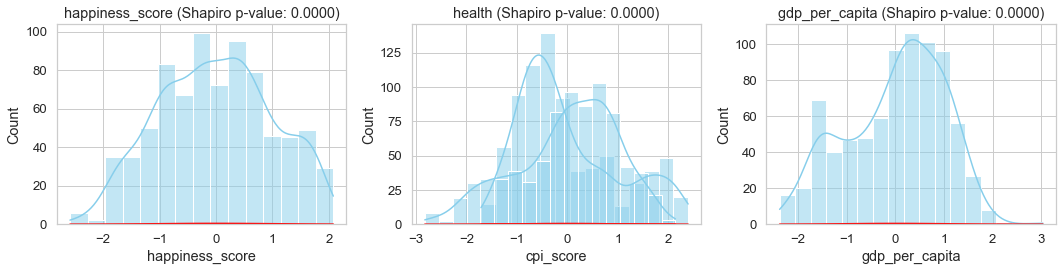

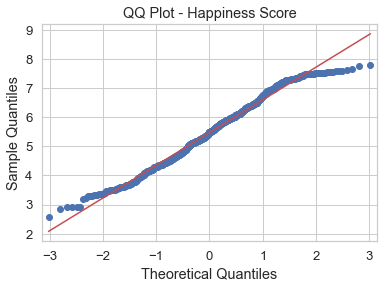

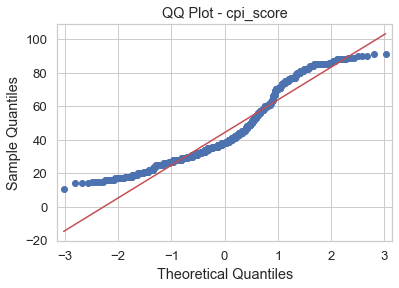

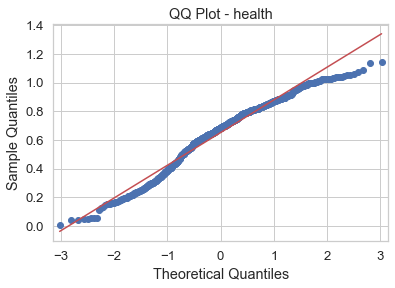

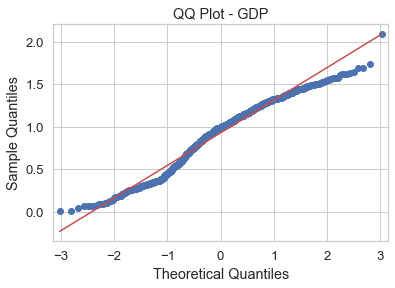

In [424]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy.stats import norm
from scipy.stats import zscore
from scipy.stats import shapiro
from statsmodels.graphics.gofplots import qqplot

# Set Seaborn style and context
sns.set(style="whitegrid", context="notebook", font_scale=1.2)

# Generate synthetic data for example (replace this with your actual data)


# Create subplots
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))

# Function to transform data to z-scores and plot normal distribution
def plot_normal_distribution(ax, data, column_name):
    z_scores = zscore(data[column_name])
    shapiro_stat, shapiro_p_value = shapiro(z_scores)
    
    sns.histplot(z_scores, kde=True, color='skyblue', ax=ax)
    x_range = np.linspace(z_scores.min(), z_scores.max(), 100)
    ax.plot(x_range, norm.pdf(x_range, 0, 1), color='red', label='Normal Dist.')
    ax.set_title(f'{column_name} (Shapiro p-value: {shapiro_p_value:.4f})')

# Plot z-scores of happiness_score with normal distribution
plot_normal_distribution(axes[0], df1, 'happiness_score')

# Plot z-scores of cpi_score with normal distribution
plot_normal_distribution(axes[1], df1, 'cpi_score')

# Plot z-scores of cpi_score with normal distribution
plot_normal_distribution(axes[1], df1, 'health')

# Plot z-scores of gdp_per_capita with normal distribution
plot_normal_distribution(axes[2], df1, 'gdp_per_capita')

# Display the plot
plt.tight_layout()
plt.show()

# QQ plots for further inspection of normality
qqplot(df1['happiness_score'], line='s')
plt.title('QQ Plot - Happiness Score')
plt.show()

qqplot(df1['cpi_score'], line='s')
plt.title('QQ Plot - cpi_score')
plt.show()

qqplot(df1['health'], line='s')
plt.title('QQ Plot - health')
plt.show()

qqplot(df1['gdp_per_capita'], line='s')
plt.title('QQ Plot - GDP')
plt.show()

## t test

In [426]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind

# Memisahkan DataFrame menjadi dua kelompok (misalnya, Var1 dan Var2 vs. Var3 dan Var4)
group1 = df1[['gdp_per_capita','cpi_score', 'health']]
group2 = df1[['happiness_score']]

# Menghitung statistik t dan p-value
t_statistic, p_value = ttest_ind(group1, group2, equal_var=False)

# Menampilkan hasil
print(f"Statistik t: {np.mean(t_statistic)}")
print(f"P-value: {np.mean(p_value)}")

# Membandingkan dengan nilai kritis dari tabel t distribusi (df = derajat kebebasan)
# Ambil df dari jumlah sampel dalam setiap kelompok dikurangi 1
df_tabel = len(group1) + len(group2) - 2

# Menggunakan alpha = 0.05 (tingkat signifikansi)
alpha = 0.05

# Menghitung nilai kritis dari distribusi t
t_critical = np.abs(t.ppf(alpha / 2, df_tabel))

print(f"Nilai Kritis: {t_critical}")

# Interpretasi
if np.mean(np.abs(t_statistic)) > t_critical or np.mean(p_value) < alpha:
    print("Kita menolak hipotesis nol dengan taraf nyata 5 % atau 95% yakin bahwa terdapat perbedaan gdp_per_capita, cpi_score, health mempengaruhi populasi skor kebahagiaan")
else:
    print("Tidak cukup bukti untuk menolak hipotesis nol dengan taraf nyata 5 % atau 95% yakin bahwa tidak terdapat perbedaan gdp_per_capita, cpi_score, health mempengaruhi populasi skor kebahagiaan")

Statistik t: -56.61514669447587
P-value: 1.2721177163995312e-278
Nilai Kritis: 1.9614646522929364
Kita menolak hipotesis nol dengan taraf nyata 5 % atau 95% yakin bahwa terdapat perbedaan gdp_per_capita, cpi_score, health mempengaruhi populasi skor kebahagiaan


## normalisasi shapiro 

In [427]:
from scipy.stats import shapiro

# Menggunakan DataFrame yang sudah dibuat sebelumnya
# df_sorted adalah DataFrame yang telah diurutkan berdasarkan happiness_score dan cpi_score
# df_filtered adalah DataFrame yang sudah difilter berdasarkan cpi_score > 50

# List variabel yang akan diuji normalitas
variabel_list = ['cpi_score', 'happiness_score', 'health', 'gdp_per_capita']

# Melakukan tes normalitas untuk setiap variabel
for variabel in variabel_list:
    stat, p_value = shapiro(df_filtered[variabel])
    
    # Menampilkan hasil tes normalitas
    print(f"Shapiro-Wilk test for {variabel}:\nStatistics={stat:.4f}, p-value={p_value:.4f}")

    # Menentukan keputusan berdasarkan nilai p-value
    alpha = 0.05
    if p_value > alpha:
        print(f"P-value ({p_value:.4f}) > alpha ({alpha}): Tidak dapat menolak hipotesis nol (data terdistribusi normal)\n")
    else:
        print(f"P-value ({p_value:.4f}) <= alpha ({alpha}): Menolak hipotesis nol (data tidak terdistribusi normal)\n")

Shapiro-Wilk test for cpi_score:
Statistics=0.8677, p-value=0.1160
P-value (0.1160) > alpha (0.05): Tidak dapat menolak hipotesis nol (data terdistribusi normal)

Shapiro-Wilk test for happiness_score:
Statistics=0.9623, p-value=0.8216
P-value (0.8216) > alpha (0.05): Tidak dapat menolak hipotesis nol (data terdistribusi normal)

Shapiro-Wilk test for health:
Statistics=0.9030, p-value=0.2698
P-value (0.2698) > alpha (0.05): Tidak dapat menolak hipotesis nol (data terdistribusi normal)

Shapiro-Wilk test for gdp_per_capita:
Statistics=0.8926, p-value=0.2121
P-value (0.2121) > alpha (0.05): Tidak dapat menolak hipotesis nol (data terdistribusi normal)



## Kurtosis

### Membuat Test Table

In [450]:
import math
df_test = df1.copy()
df_test

,Country,happiness_score,gdp_per_capita,family,health,freedom,generosity,government_trust,dystopia_residual,continent,Year,social_support,cpi_score
0,Norway,7.5370,1.616463,1.533524,0.796667,0.635423,0.362012,0.315964,2.277027,Europe,2015,0.609302,88
1,Denmark,7.5220,1.482383,1.551122,0.792566,0.626007,0.355280,0.400770,2.313707,Europe,2015,0.609302,91
2,Iceland,7.5040,1.480633,1.610574,0.833552,0.627163,0.475540,0.153527,2.322715,Europe,2015,0.609302,79
3,Switzerland,7.4940,1.564980,1.516912,0.858131,0.620071,0.290549,0.367007,2.276716,Europe,2015,0.609302,86
4,Finland,7.4690,1.443572,1.540247,0.809158,0.617951,0.245483,0.382612,2.430182,Europe,2015,0.609302,90
...,...,...,...,...,...,...,...,...,...,...,...,...,...
787,Botswana,3.4789,0.997549,0.504998,0.494102,0.509089,0.033407,0.101786,0.257241,Africa,2020,1.085695,60
788,Tanzania,3.4762,0.457163,0.504998,0.442678,0.509343,0.271541,0.203881,0.718963,Africa,2020,0.872675,38
789,Rwanda,3.3123,0.343243,0.504998,0.572383,0.604088,0.235705,0.485542,0.548445,Africa,2020,0.522876,54
790,Zimbabwe,3.2992,0.425564,0.504998,0.375038,0.377405,0.151349,0.080929,0.841031,Africa,2020,1.047835,24


In [451]:
to_drop = ['family','freedom', 'generosity', 'government_trust', 'dystopia_residual','social_support']
df_test.drop(columns=to_drop, inplace=True)

### Membuat Fungsi Kurtosis dan Distribusi Normal

In [452]:
# Membuat perhitungan Derajat Kurtosis
def normal_dist_equation(x, mean, std):
    pi = math.pi
    e_value = math.e
    left_equ = 1 / (std * ((2*pi)**1/2))
    right_equ = (e_value)**((-1/2)*(((x - mean) / std)**2))
    fx = left_equ * right_equ
    return fx

def kurtosis_v(data, table_name):
    mean_data = data.mean()
    std_data = data.std()
    for_sum = []
    for i in range(len(data)):
        seegma = (data[i] - mean_data)**4
        for_sum.append(seegma)

    summary = np.sum(for_sum)
    kurtosis_value = ((1/len(data))*summary)/((std_data)**4)

    if kurtosis_value < 3:
        jenis_kurtosis = "Platykurtic"
    elif kurtosis_value == 3:
        jenis_kurtosis = "Mesokurtic"
    elif kurtosis_value > 3:
        jenis_kurtosis = "Leptokurtic"

    return print(f"Nilai kurtosis dari distribusi data kolom {table_name} adalah {kurtosis_value}.",
                 f"\nDistribusi data mengarah ke {jenis_kurtosis}.")

# Membuat fungsi yang menampilkan Distribusi Normal
def normal_kurtosis(data, table_name):
    mean_data = data.mean()
    std_data = data.std()
    fx_list_kurtosis = []
    for i in range(len(data)):
        x = data[i]
        ke_list_kurtos = normal_dist_equation(x, mean_data, std_data)
        fx_list_kurtosis.append(ke_list_kurtos)

    df_kurtos = pd.DataFrame()
    df_kurtos["x"] = data
    df_kurtos["f(x)"]=fx_list_kurtosis
    sorted_df_kurtos = df_kurtos.sort_values(by="x")
    sorted_df_kurtos_reset = sorted_df_kurtos.reset_index()
    to_drop = ['index']
    sorted_df_kurtos_reset.drop(columns=to_drop, inplace=True)
    plt.plot(sorted_df_kurtos_reset["x"], sorted_df_kurtos_reset["f(x)"], color='blue', linewidth=2, label='Normal Distribution')

    # Customize the plot
    plt.xlabel('X-axis')
    plt.ylabel('Probability Density')
    plt.title(table_name)
    plt.legend()

### Happiness Score

Nilai kurtosis dari distribusi data kolom happiness_score adalah 2.2456202219849293. 
Distribusi data mengarah ke Platykurtic.


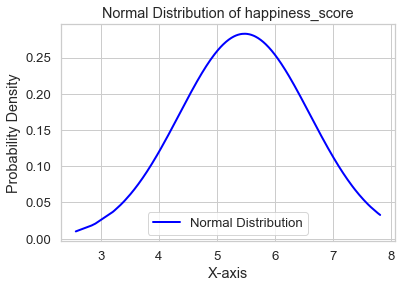

In [453]:
normal_kurtosis(df_test["happiness_score"], "Normal Distribution of happiness_score")
kurtosis_v(df_test["happiness_score"], "happiness_score")

### GDP per-Capita

Nilai kurtosis dari distribusi data kolom gdp_per_capita adalah 2.3106610155994676. 
Distribusi data mengarah ke Platykurtic.


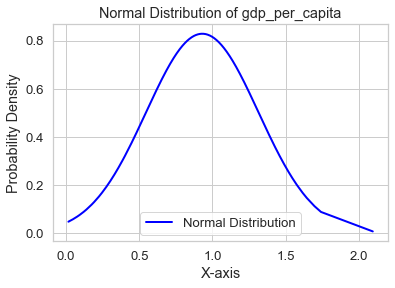

In [454]:
normal_kurtosis(df_test["gdp_per_capita"], "Normal Distribution of gdp_per_capita")
kurtosis_v(df_test["gdp_per_capita"], "gdp_per_capita")

### Health

Nilai kurtosis dari distribusi data kolom health adalah 2.6372702573867937. 
Distribusi data mengarah ke Platykurtic.


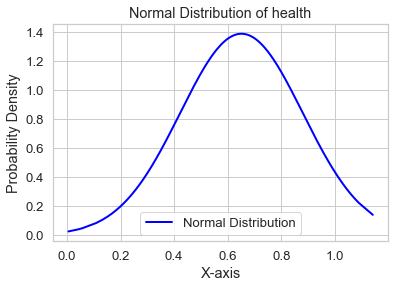

In [455]:
normal_kurtosis(df_test["health"], "Normal Distribution of health")
kurtosis_v(df_test["health"], "health")

### CPI Score

Nilai kurtosis dari distribusi data kolom cpi_score adalah 2.5479838244674573. 
Distribusi data mengarah ke Platykurtic.


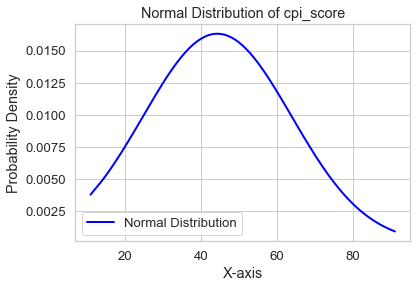

In [456]:
normal_kurtosis(df_test["cpi_score"], "Normal Distribution of cpi_score")
kurtosis_v(df_test["cpi_score"], "cpi_score")

# Analisis Korelasi

## BIVARIATE

In [429]:
# melakukan analisis korelasi menggunakan metode pearson, kolom yang isinya berupa string dibuang terlebih dahulu
df1_1 = df1.drop(['Year', 'Country', 'continent'], axis=1)
df1_1.corr(method='pearson')

,happiness_score,gdp_per_capita,family,health,freedom,generosity,government_trust,dystopia_residual,social_support,cpi_score
happiness_score,1.000000,0.791582,0.275522,0.756352,0.533434,0.154158,0.456680,0.345713,0.312251,0.693001
gdp_per_capita,0.791582,1.000000,0.321600,0.767772,0.332739,-0.010135,0.363217,0.073026,0.229879,0.703116
family,0.275522,0.321600,1.000000,0.063569,0.113826,0.230815,0.143822,0.312755,-0.631757,0.214239
health,0.756352,0.767772,0.063569,1.000000,0.377043,-0.013952,0.316772,0.006431,0.436514,0.646920
freedom,0.533434,0.332739,0.113826,0.377043,1.000000,0.279614,0.466598,-0.007717,0.253305,0.475186
generosity,0.154158,-0.010135,0.230815,-0.013952,0.279614,1.000000,0.278017,0.075980,-0.188554,0.169662
government_trust,0.456680,0.363217,0.143822,0.316772,0.466598,0.278017,1.000000,0.084116,0.036561,0.619796
dystopia_residual,0.345713,0.073026,0.312755,0.006431,-0.007717,0.075980,0.084116,1.000000,-0.403578,0.059145
social_support,0.312251,0.229879,-0.631757,0.436514,0.253305,-0.188554,0.036561,-0.403578,1.000000,0.193674
cpi_score,0.693001,0.703116,0.214239,0.646920,0.475186,0.169662,0.619796,0.059145,0.193674,1.000000


## MULTIVARIATE

In [432]:
import pandas as pd
import numpy as np

# Menghitung koefisien korelasi
correlation_matrix = df1[['cpi_score', 'health', 'gdp_per_capita', 'happiness_score']].corr()

# Menampilkan matriks korelasi
print("Matriks Korelasi:")
print(correlation_matrix)

# Menampilkan koefisien korelasi antara variabel
cpi_health_correlation = correlation_matrix.loc['happiness_score', 'health']
cpi_gdp_correlation = correlation_matrix.loc['happiness_score', 'gdp_per_capita']
cpi_happiness_correlation = correlation_matrix.loc['happiness_score', 'cpi_score']

# Menyimpan hasil korelasi dalam DataFrame
correlation_results = pd.DataFrame({
    'Variable': ['cpi_score', 'health', 'gdp_per_capita', 'happiness_score'],
    'CPI_Score_Correlation': [correlation_matrix.loc['happiness_score', 'happiness_score'],
                               correlation_matrix.loc['happiness_score', 'health'],
                               correlation_matrix.loc['happiness_score', 'gdp_per_capita'],
                               correlation_matrix.loc['happiness_score', 'cpi_score']],
    'Interpretation': [
        'Self-Correlation',
        'Strong positive correlation (> 0.50) with Happiness_Score',
        'Strong positive correlation (> 0.50) with Happiness_Score',
        'Strong positive correlation (> 0.50) with Happiness_Score and Happiness_Score'
    ]
})

print("Interpretasi:")
correlation_results


Matriks Korelasi:
                 cpi_score    health  gdp_per_capita  happiness_score
cpi_score         1.000000  0.646920        0.703116         0.693001
health            0.646920  1.000000        0.767772         0.756352
gdp_per_capita    0.703116  0.767772        1.000000         0.791582
happiness_score   0.693001  0.756352        0.791582         1.000000
Interpretasi:


,Variable,CPI_Score_Correlation,Interpretation
0,cpi_score,1.000000,Self-Correlation
1,health,0.756352,Strong positive correlation (> 0.50) with Happ...
2,gdp_per_capita,0.791582,Strong positive correlation (> 0.50) with Happ...
3,happiness_score,0.693001,Strong positive correlation (> 0.50) with Happ...


# HEATMAP

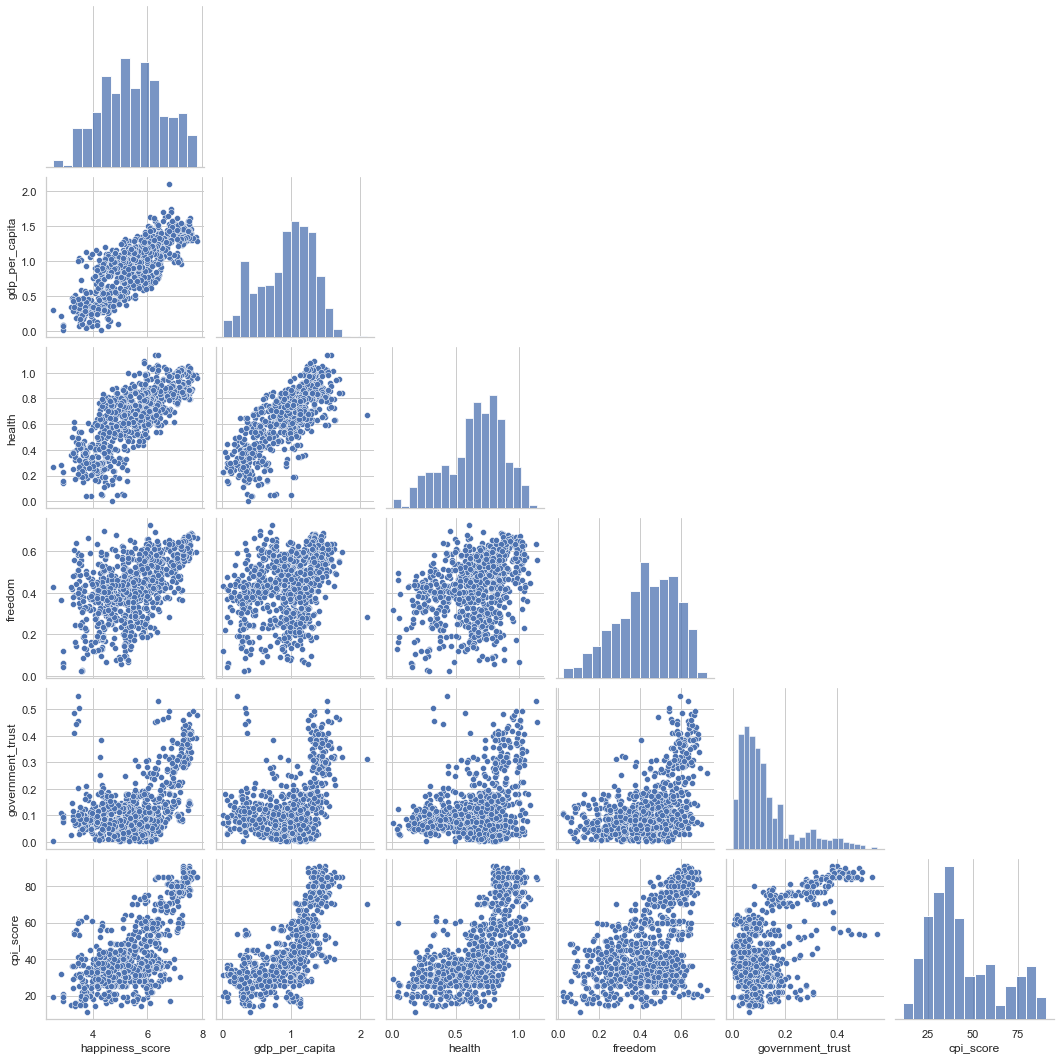

In [296]:
vars_screened = ['happiness_score','gdp_per_capita','health','freedom','government_trust','cpi_score']
sns.pairplot(data=df1.reset_index(), vars=vars_screened , corner=True);

<AxesSubplot:>

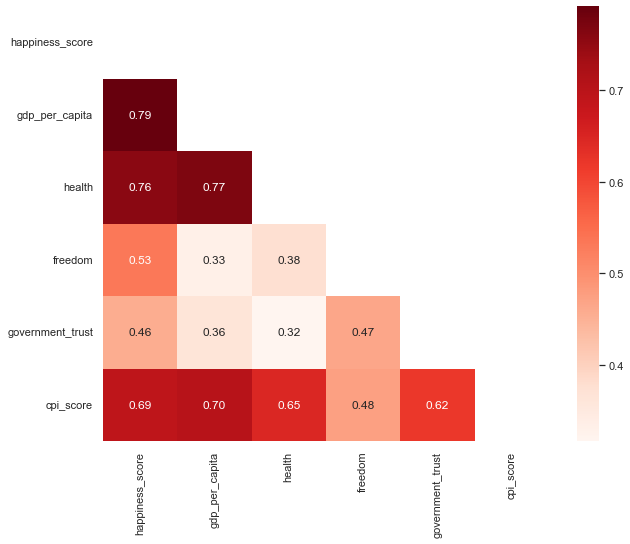

In [297]:
dfcorr = df1[vars_screened].corr()
dfcorr.style.format('{:.2f}')
mask=np.zeros_like(dfcorr)
mask[np.triu_indices_from(mask)]=True

plt.figure(figsize=(10,8))
sns.heatmap(dfcorr, cmap='Reds', annot=True, fmt='.2f', mask=mask)

# TIME SERIES ANALYSIS

In [299]:
#Importing the basic librarires fot analysis

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
plt.style.use("ggplot")  #using style ggplot

%matplotlib inline
from mpl_toolkits.mplot3d import Axes3D
import datetime as dt
import plotly.graph_objects as go
import plotly.express as px

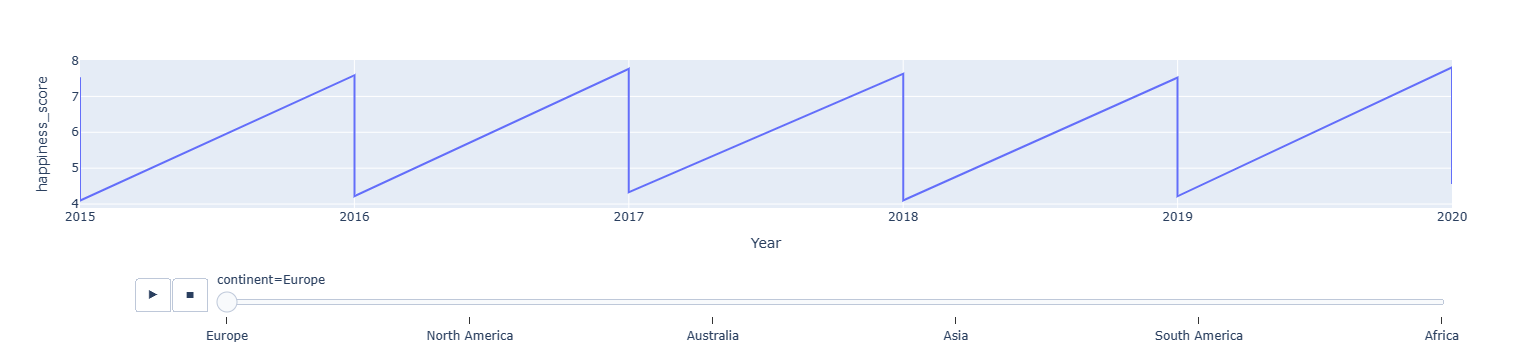

In [304]:
px.line(df1, x="Year",y="happiness_score",animation_frame="continent")

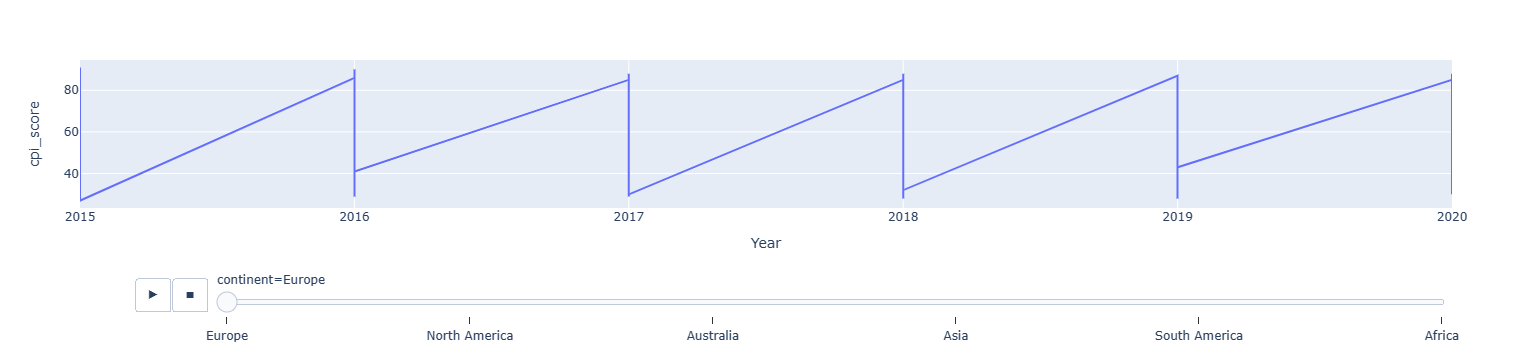

In [307]:
px.line(df1, x="Year",y="cpi_score",animation_frame="continent")

# Visualisasi Data dan Visualisasi data interaktif

<AxesSubplot:xlabel='happiness_score', ylabel='continent'>

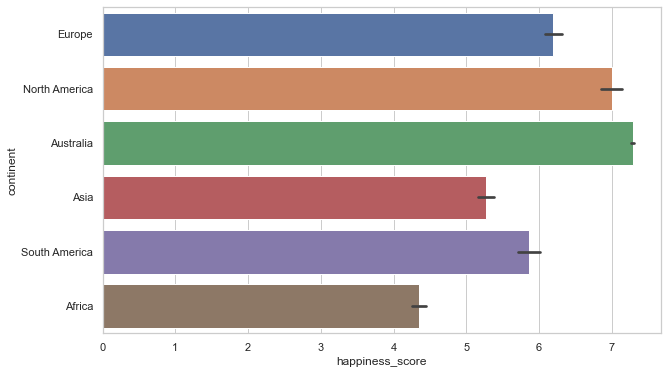

In [292]:
plt.figure(figsize=(10,6))
sns.barplot(data=df1,y='continent', x='happiness_score')

C:\Users\Gorfy\AppData\Local\Temp\ipykernel_13848\2376567704.py:9: MatplotlibDeprecationWarning:

Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.



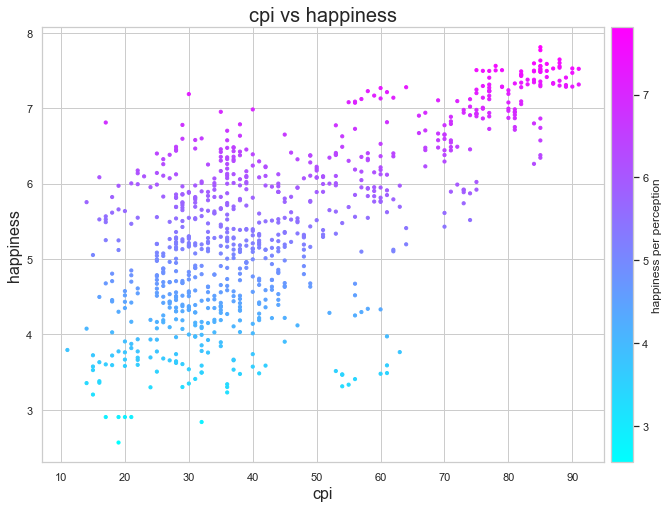

In [294]:
happiness = df1.happiness_score
cpi = df1.cpi_score

plt.figure(figsize=(12,8))
scatter_hpc = plt.scatter(cpi,happiness,s=10, c=happiness , cmap='cool')
plt.xlabel('cpi', fontsize='16')
plt.ylabel('happiness', fontsize='16')
plt.title('cpi vs happiness', fontsize='20')
plt.colorbar(scatter_hpc, label='happiness per perception',
              orientation='vertical', location='right', pad=.01);

# Bar Chart

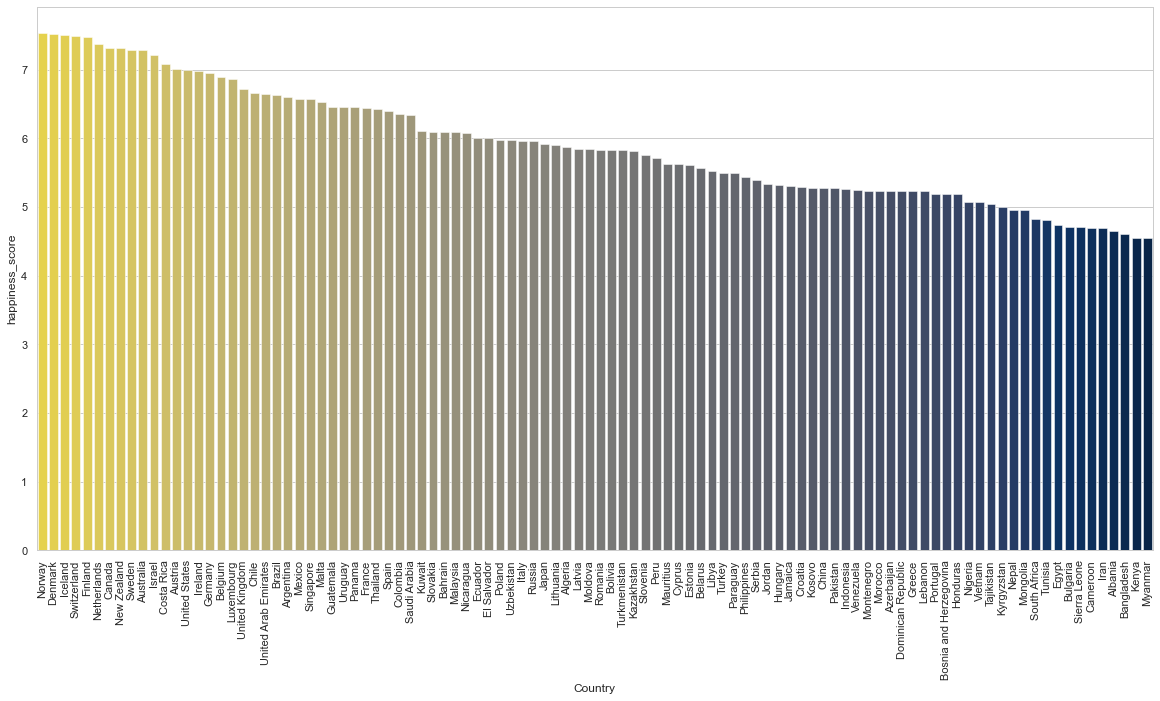

In [302]:
with sns.axes_style("whitegrid"):
    plt.subplots(figsize=(20,10))
    sns.barplot(data=df1,x=df1["Country"][:100], y="happiness_score",palette=("cividis_r"))
plt.xticks(rotation=90)  
plt.show()